In [5]:
{
  "nbformat": 4,
  "nbformat_minor": 0,
  "metadata": {
    "colab": {
      "provenance": []
    },
    "kernelspec": {
      "name": "python3",
      "display_name": "Python 3"
    },
    "language_info": {
      "name": "python"
    }
  },
  "cells": [
    {
      "cell_type": "code",
      "execution_count": 1,
      "metadata": {
        "colab": {
          "base_uri": "https://localhost:8080/",
          "height": 327
        },
        "id": "yhuo8m61_neU",
        "outputId": "359b6e59-74ab-41cb-c538-a9d474f90ef4"
      },
      "outputs": [
        {
          "output_type": "display_data",
          "data": {
            "text/plain": [
              "<Figure size 1820x520 with 3 Axes>"
            ],
            "image/png": "...\n"
          },
          "metadata": {}
        }
      ],
      "source": [
        "import numpy as np\n",
        "import matplotlib.pyplot as plt\n",
        "from scipy.stats import norm\n",
        "\n",
        "# -----------------------------\n",
        "# Product parameters (adjust as needed)\n",
        "# -----------------------------\n",
        "products = {\n",
        "    \"Product A\": {\"sigma\": 65, \"L\": 2, \"h\": 1.1},\n",
        "    \"Product B\": {\"sigma\": 100, \"L\": 3, \"h\": 1.3},\n",
        "    \"Product C\": {\"sigma\": 55, \"L\": 4, \"h\": 1.8},\n",
        "}\n",
        "\n",
        "# Service levels from 0.80 to 0.99\n",
        "service_levels = np.round(np.arange(0.80, 0.991, 0.01), 2)\n",
        "z = norm.ppf(service_levels)\n",
        "\n",
        "# -----------------------------\n",
        "# Plot setup\n",
        "# -----------------------------\n",
        "plt.rcParams.update({\n",
        "    \"figure.dpi\": 130,\n",
        "    \"axes.spines.top\": True,\n",
        "    \"axes.spines.right\": True,\n",
        "    \"axes.grid\": True,\n",
        "    \"grid.alpha\": 0.3\n",
        "})\n",
        "\n",
        "fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)\n",
        "fig.suptitle(\"Service Level Trade-offs in Inventory Optimization\", fontsize=13, fontweight='bold')\n",
        "\n",
        "# -----------------------------\n",
        "# Generate each subplot\n",
        "# -----------------------------\n",
        "for ax, (name, p) in zip(axes, products.items()):\n",
        "    # Safety Stock & Holding Cost calculations\n",
        "    safety_stock = z * p[\"sigma\"] * np.sqrt(p[\"L\"])\n",
        "    holding_cost = safety_stock * p[\"h\"]\n",
        "\n",
        "    # Plot curves\n",
        "    ax.plot(service_levels, safety_stock, color=\"tab:blue\", linewidth=2, marker=\"o\", markersize=4, label=\"Safety Stock\")\n",
        "    ax.plot(service_levels, holding_cost, color=\"tab:green\", linewidth=2, marker=\"s\", markersize=4, label=\"Holding Cost\")\n",
        "\n",
        "    # Titles and labels\n",
        "    ax.set_title(name, fontsize=11, fontweight='bold')\n",
        "    ax.set_xlabel(\"Service Level\")\n",
        "    ax.set_xlim(0.80, 0.99)\n",
        "    ax.set_xticks([0.80, 0.85, 0.90, 0.95, 0.99])\n",
        "    ax.set_xticklabels([\"80%\", \"85%\", \"90%\", \"95%\", \"99%\"])\n",
        "    ax.grid(True, linestyle=\"--\", alpha=0.4)\n",
        "\n",
        "    # Legend inside each subplot (top-right corner)\n",
        "    ax.legend(loc=\"upper right\", fontsize=9, frameon=False)\n",
        "\n",
        "# Shared y-label\n",
        "axes[0].set_ylabel(\"Units / Cost\", fontsize=10, fontweight='bold')\n",
        "\n",
        "plt.tight_layout(rect=[0, 0, 1, 0.92])\n",
        "plt.show()\n"
      ]
    },
    {
      "cell_type": "code",
      "source": [],
      "metadata": {
        "id": "6Dj-V-Pn_onG"
      },
      #"execution_count": null,
      "outputs": []
    }
  ]
}

{'nbformat': 4,
 'nbformat_minor': 0,
 'metadata': {'colab': {'provenance': []},
  'kernelspec': {'name': 'python3', 'display_name': 'Python 3'},
  'language_info': {'name': 'python'}},
 'cells': [{'cell_type': 'code',
   'execution_count': 1,
   'metadata': {'colab': {'base_uri': 'https://localhost:8080/',
     'height': 327},
    'id': 'yhuo8m61_neU',
    'outputId': '359b6e59-74ab-41cb-c538-a9d474f90ef4'},
   'outputs': [{'output_type': 'display_data',
     'data': {'text/plain': ['<Figure size 1820x520 with 3 Axes>'],
      'image/png': '...\n'},
     'metadata': {}}],
   'source': ['import numpy as np\n',
    'import matplotlib.pyplot as plt\n',
    'from scipy.stats import norm\n',
    '\n',
    '# -----------------------------\n',
    '# Product parameters (adjust as needed)\n',
    '# -----------------------------\n',
    'products = {\n',
    '    "Product A": {"sigma": 65, "L": 2, "h": 1.1},\n',
    '    "Product B": {"sigma": 100, "L": 3, "h": 1.3},\n',
    '    "Product C":

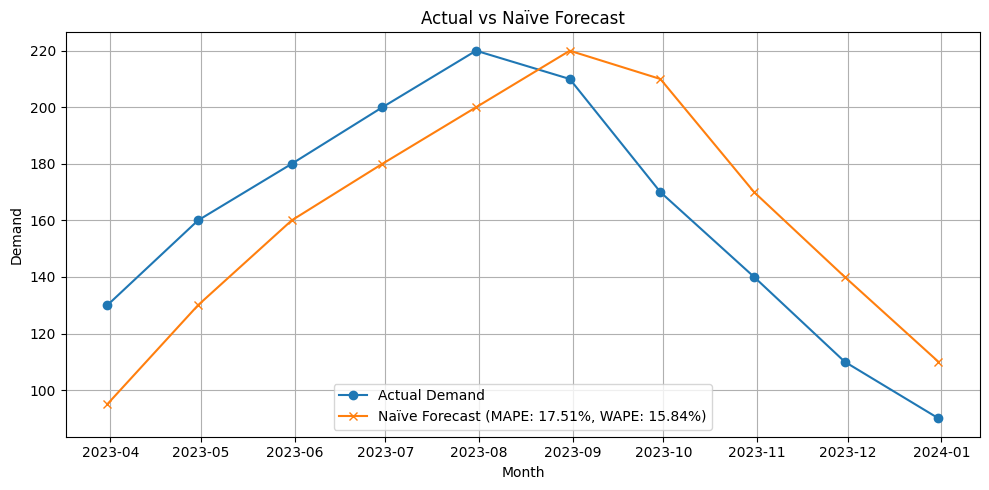

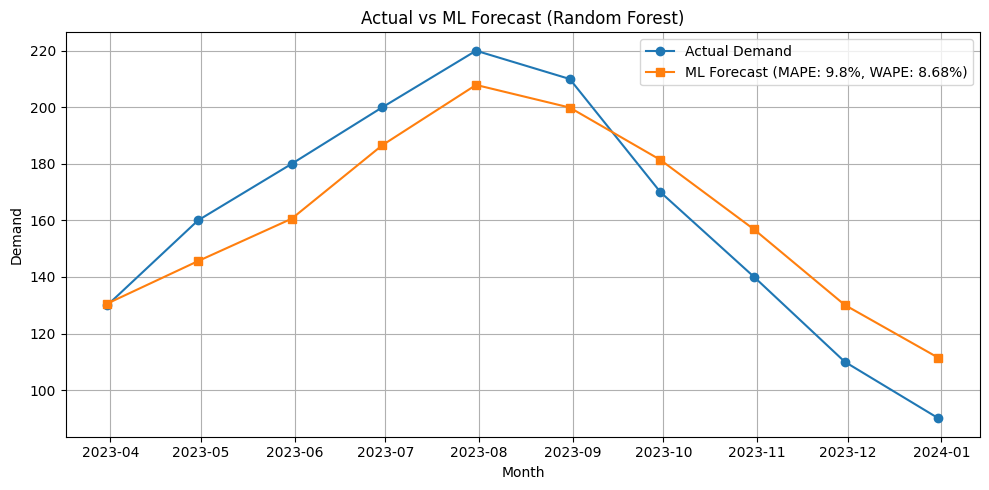

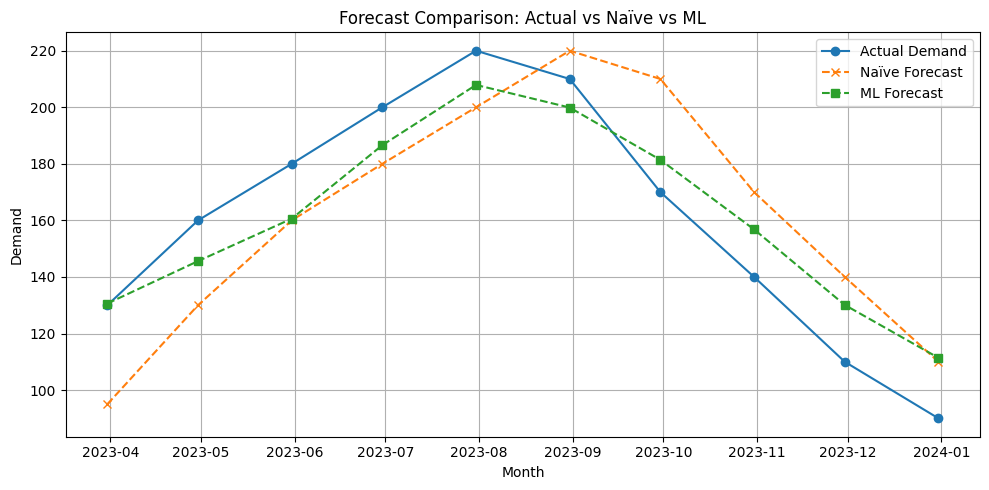

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

# Simulated monthly demand data
data = {
    'Month': pd.date_range(start='2023-01-01', periods=12, freq='ME'),
    'Demand': [80, 95, 130, 160, 180, 200, 220, 210, 170, 140, 110, 90]
}
df = pd.DataFrame(data)

# Naïve Forecast: Previous month’s demand
df['Naive_Forecast'] = df['Demand'].shift(1)

# ML Forecast: Using Lag1 and Lag2 features
df['Lag1'] = df['Demand'].shift(1)
df['Lag2'] = df['Demand'].shift(2)
df.dropna(inplace=True)

X = df[['Lag1', 'Lag2']]
y = df['Demand']

model = RandomForestRegressor(random_state=44)
model.fit(X, y)
df['ML_Forecast'] = model.predict(X)

# Evaluation Metrics
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def wape(y_true, y_pred):
    return np.sum(np.abs(y_true - y_pred)) / np.sum(y_true) * 100

mape_naive = round(mape(df['Demand'], df['Naive_Forecast']), 2)
mape_ml = round(mape(df['Demand'], df['ML_Forecast']), 2)
wape_naive = round(wape(df['Demand'], df['Naive_Forecast']), 2)
wape_ml = round(wape(df['Demand'], df['ML_Forecast']), 2)

# Plot 1: Actual vs Naïve Forecast
plt.figure(figsize=(10, 5))
plt.plot(df['Month'], df['Demand'], label='Actual Demand', marker='o')
plt.plot(df['Month'], df['Naive_Forecast'], label=f'Naïve Forecast (MAPE: {mape_naive}%, WAPE: {wape_naive}%)', marker='x')
plt.title('Actual vs Naïve Forecast')
plt.xlabel('Month')
plt.ylabel('Demand')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot 2: Actual vs ML Forecast
plt.figure(figsize=(10, 5))
plt.plot(df['Month'], df['Demand'], label='Actual Demand', marker='o')
plt.plot(df['Month'], df['ML_Forecast'], label=f'ML Forecast (MAPE: {mape_ml}%, WAPE: {wape_ml}%)', marker='s')
plt.title('Actual vs ML Forecast (Random Forest)')
plt.xlabel('Month')
plt.ylabel('Demand')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot 3: Combined Comparison
plt.figure(figsize=(10, 5))
plt.plot(df['Month'], df['Demand'], label='Actual Demand', marker='o')
plt.plot(df['Month'], df['Naive_Forecast'], label='Naïve Forecast', linestyle='--', marker='x')
plt.plot(df['Month'], df['ML_Forecast'], label='ML Forecast', linestyle='--', marker='s')
plt.title('Forecast Comparison: Actual vs Naïve vs ML')
plt.xlabel('Month')
plt.ylabel('Demand')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

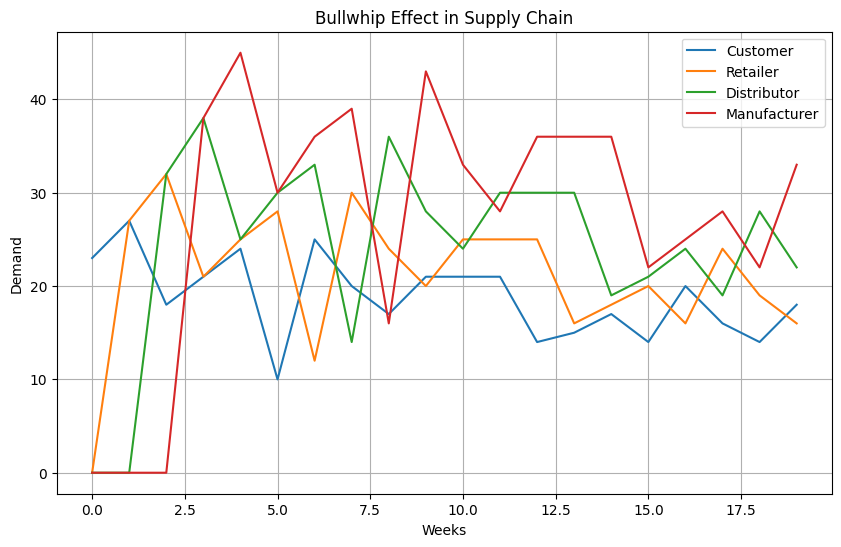

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
weeks = 20
customer_demand = np.random.poisson(20, weeks)

# Bullwhip simulation: each tier reacts with delay and amplification
def simulate_bullwhip(demand, delay=1, amplification=1.2):
    tiers = [demand]
    for i in range(3):  # Retailer, Distributor, Manufacturer
        tier_demand = np.zeros_like(demand)
        for t in range(delay, weeks):
            tier_demand[t] = amplification * tiers[-1][t - delay]
        tiers.append(tier_demand)
    return tiers

tiers = simulate_bullwhip(customer_demand)

# Plotting
plt.figure(figsize=(10, 6))
labels = ['Customer', 'Retailer', 'Distributor', 'Manufacturer']
for i, tier in enumerate(tiers):
    plt.plot(tier, label=labels[i])
plt.title('Bullwhip Effect in Supply Chain')
plt.xlabel('Weeks')
plt.ylabel('Demand')
plt.legend()
plt.grid(True)
plt.show()

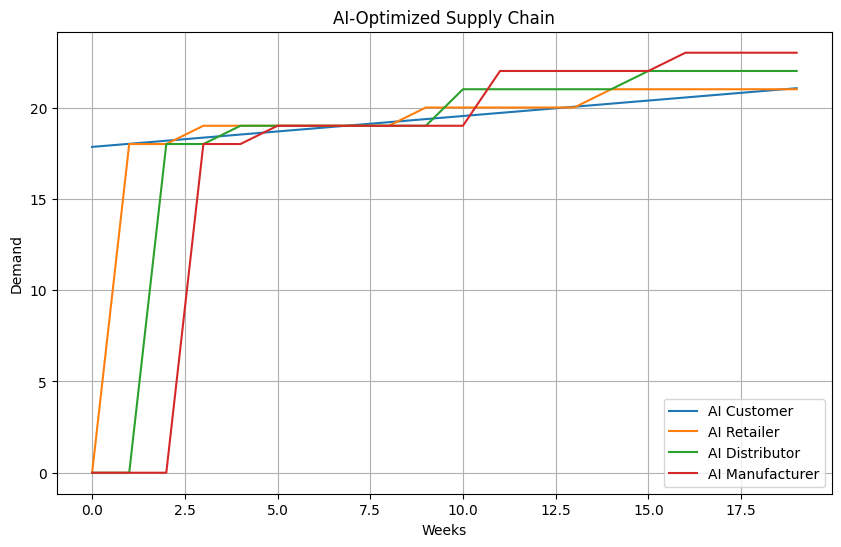

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Parameters from previous cell to ensure execution context
weeks = 20
customer_demand = np.random.poisson(20, weeks)
labels = ['Customer', 'Retailer', 'Distributor', 'Manufacturer']

# AI Forecasting: simple linear model to predict next week's demand
def ai_forecast(demand):
    X = np.arange(len(demand)).reshape(-1, 1)
    model = LinearRegression().fit(X, demand)
    forecast = model.predict(X)
    return forecast

# AI Routing: dampen amplification based on forecast accuracy
def simulate_ai_supply_chain(demand, delay=1, amplification=1.05):
    forecast = ai_forecast(demand)
    tiers = [forecast]
    for i in range(3):
        tier_demand = np.zeros_like(demand)
        for t in range(delay, weeks):
            tier_demand[t] = amplification * tiers[-1][t - delay]
        tiers.append(tier_demand)
    return tiers

ai_tiers = simulate_ai_supply_chain(customer_demand)

# Plotting
plt.figure(figsize=(10, 6))
for i, tier in enumerate(ai_tiers):
    plt.plot(tier, label=f'AI {labels[i]}')
plt.title('AI-Optimized Supply Chain')
plt.xlabel('Weeks')
plt.ylabel('Demand')
plt.legend()
plt.grid(True)
plt.show()

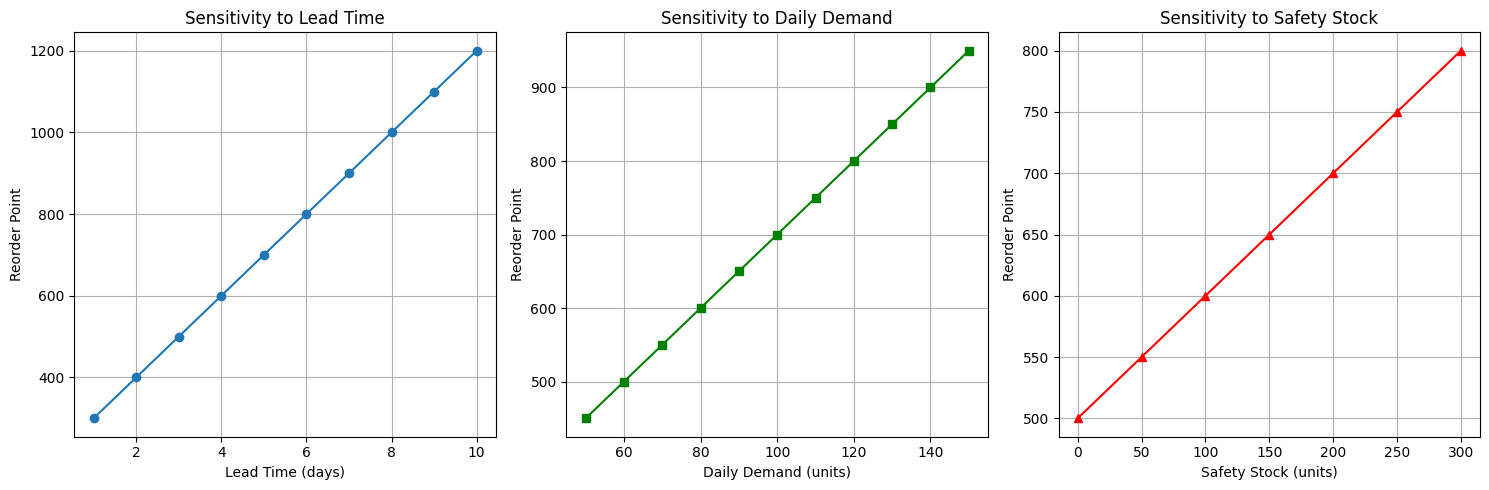

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Base parameters
daily_demand = 100         # units/day
lead_time = 5              # days
safety_stock = 200         # units

# Reorder Point Calculation
def calculate_reorder_point(demand, lead, safety):
    return (demand * lead) + safety

# Sensitivity Analysis: vary one parameter at a time
lead_times = np.arange(1, 11)  # 1 to 10 days
demands = np.arange(50, 151, 10)  # 50 to 150 units/day
safety_stocks = np.arange(0, 301, 50)  # 0 to 300 units

# 1. Sensitivity to Lead Time
rp_lead = [calculate_reorder_point(daily_demand, lt, safety_stock) for lt in lead_times]

# 2. Sensitivity to Daily Demand
rp_demand = [calculate_reorder_point(d, lead_time, safety_stock) for d in demands]

# 3. Sensitivity to Safety Stock
rp_safety = [calculate_reorder_point(daily_demand, lead_time, ss) for ss in safety_stocks]

# Plotting
plt.figure(figsize=(15, 5))

# Lead Time Sensitivity
plt.subplot(1, 3, 1)
plt.plot(lead_times, rp_lead, marker='o')
plt.title('Sensitivity to Lead Time')
plt.xlabel('Lead Time (days)')
plt.ylabel('Reorder Point')
plt.grid(True)

# Demand Sensitivity
plt.subplot(1, 3, 2)
plt.plot(demands, rp_demand, marker='s', color='green')
plt.title('Sensitivity to Daily Demand')
plt.xlabel('Daily Demand (units)')
plt.ylabel('Reorder Point')
plt.grid(True)

# Safety Stock Sensitivity
plt.subplot(1, 3, 3)
plt.plot(safety_stocks, rp_safety, marker='^', color='red')
plt.title('Sensitivity to Safety Stock')
plt.xlabel('Safety Stock (units)')
plt.ylabel('Reorder Point')
plt.grid(True)

plt.tight_layout()
plt.show()